<center><h1>Wagner_Anton_HW5</h1></center>
<br>
<br>

Name: Anton Wagner
<br>
Github Username: AntonW1
<br>
USC ID: 2245157283

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.tree import _tree
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
import math
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import cross_val_score

In [2]:
!pip install xgboost

In [3]:
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [4]:
data_path = '../Homework 5 Data/diagnosis.csv'

columns = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing',
           'micturition_pains', 'urethra_issues', 'inflammation', 'nephritis']

df = pd.read_csv(data_path, names=columns, sep='\t', decimal=',', encoding='utf-16')
df

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,urethra_issues,inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no
...,...,...,...,...,...,...,...,...
115,41.4,no,yes,yes,no,yes,no,yes
116,41.5,no,no,no,no,no,no,no
117,41.5,yes,yes,no,yes,no,no,yes
118,41.5,no,yes,yes,no,yes,no,yes


### (b) Build a decision tree

In [5]:
binary = {'no': 0, 'yes': 1}
x = df.drop(columns=['inflammation', 'nephritis'])
x = x.replace(binary)

y = 'bladder: ' + df['inflammation'] + ', ' + 'nephritis: ' + df['nephritis']

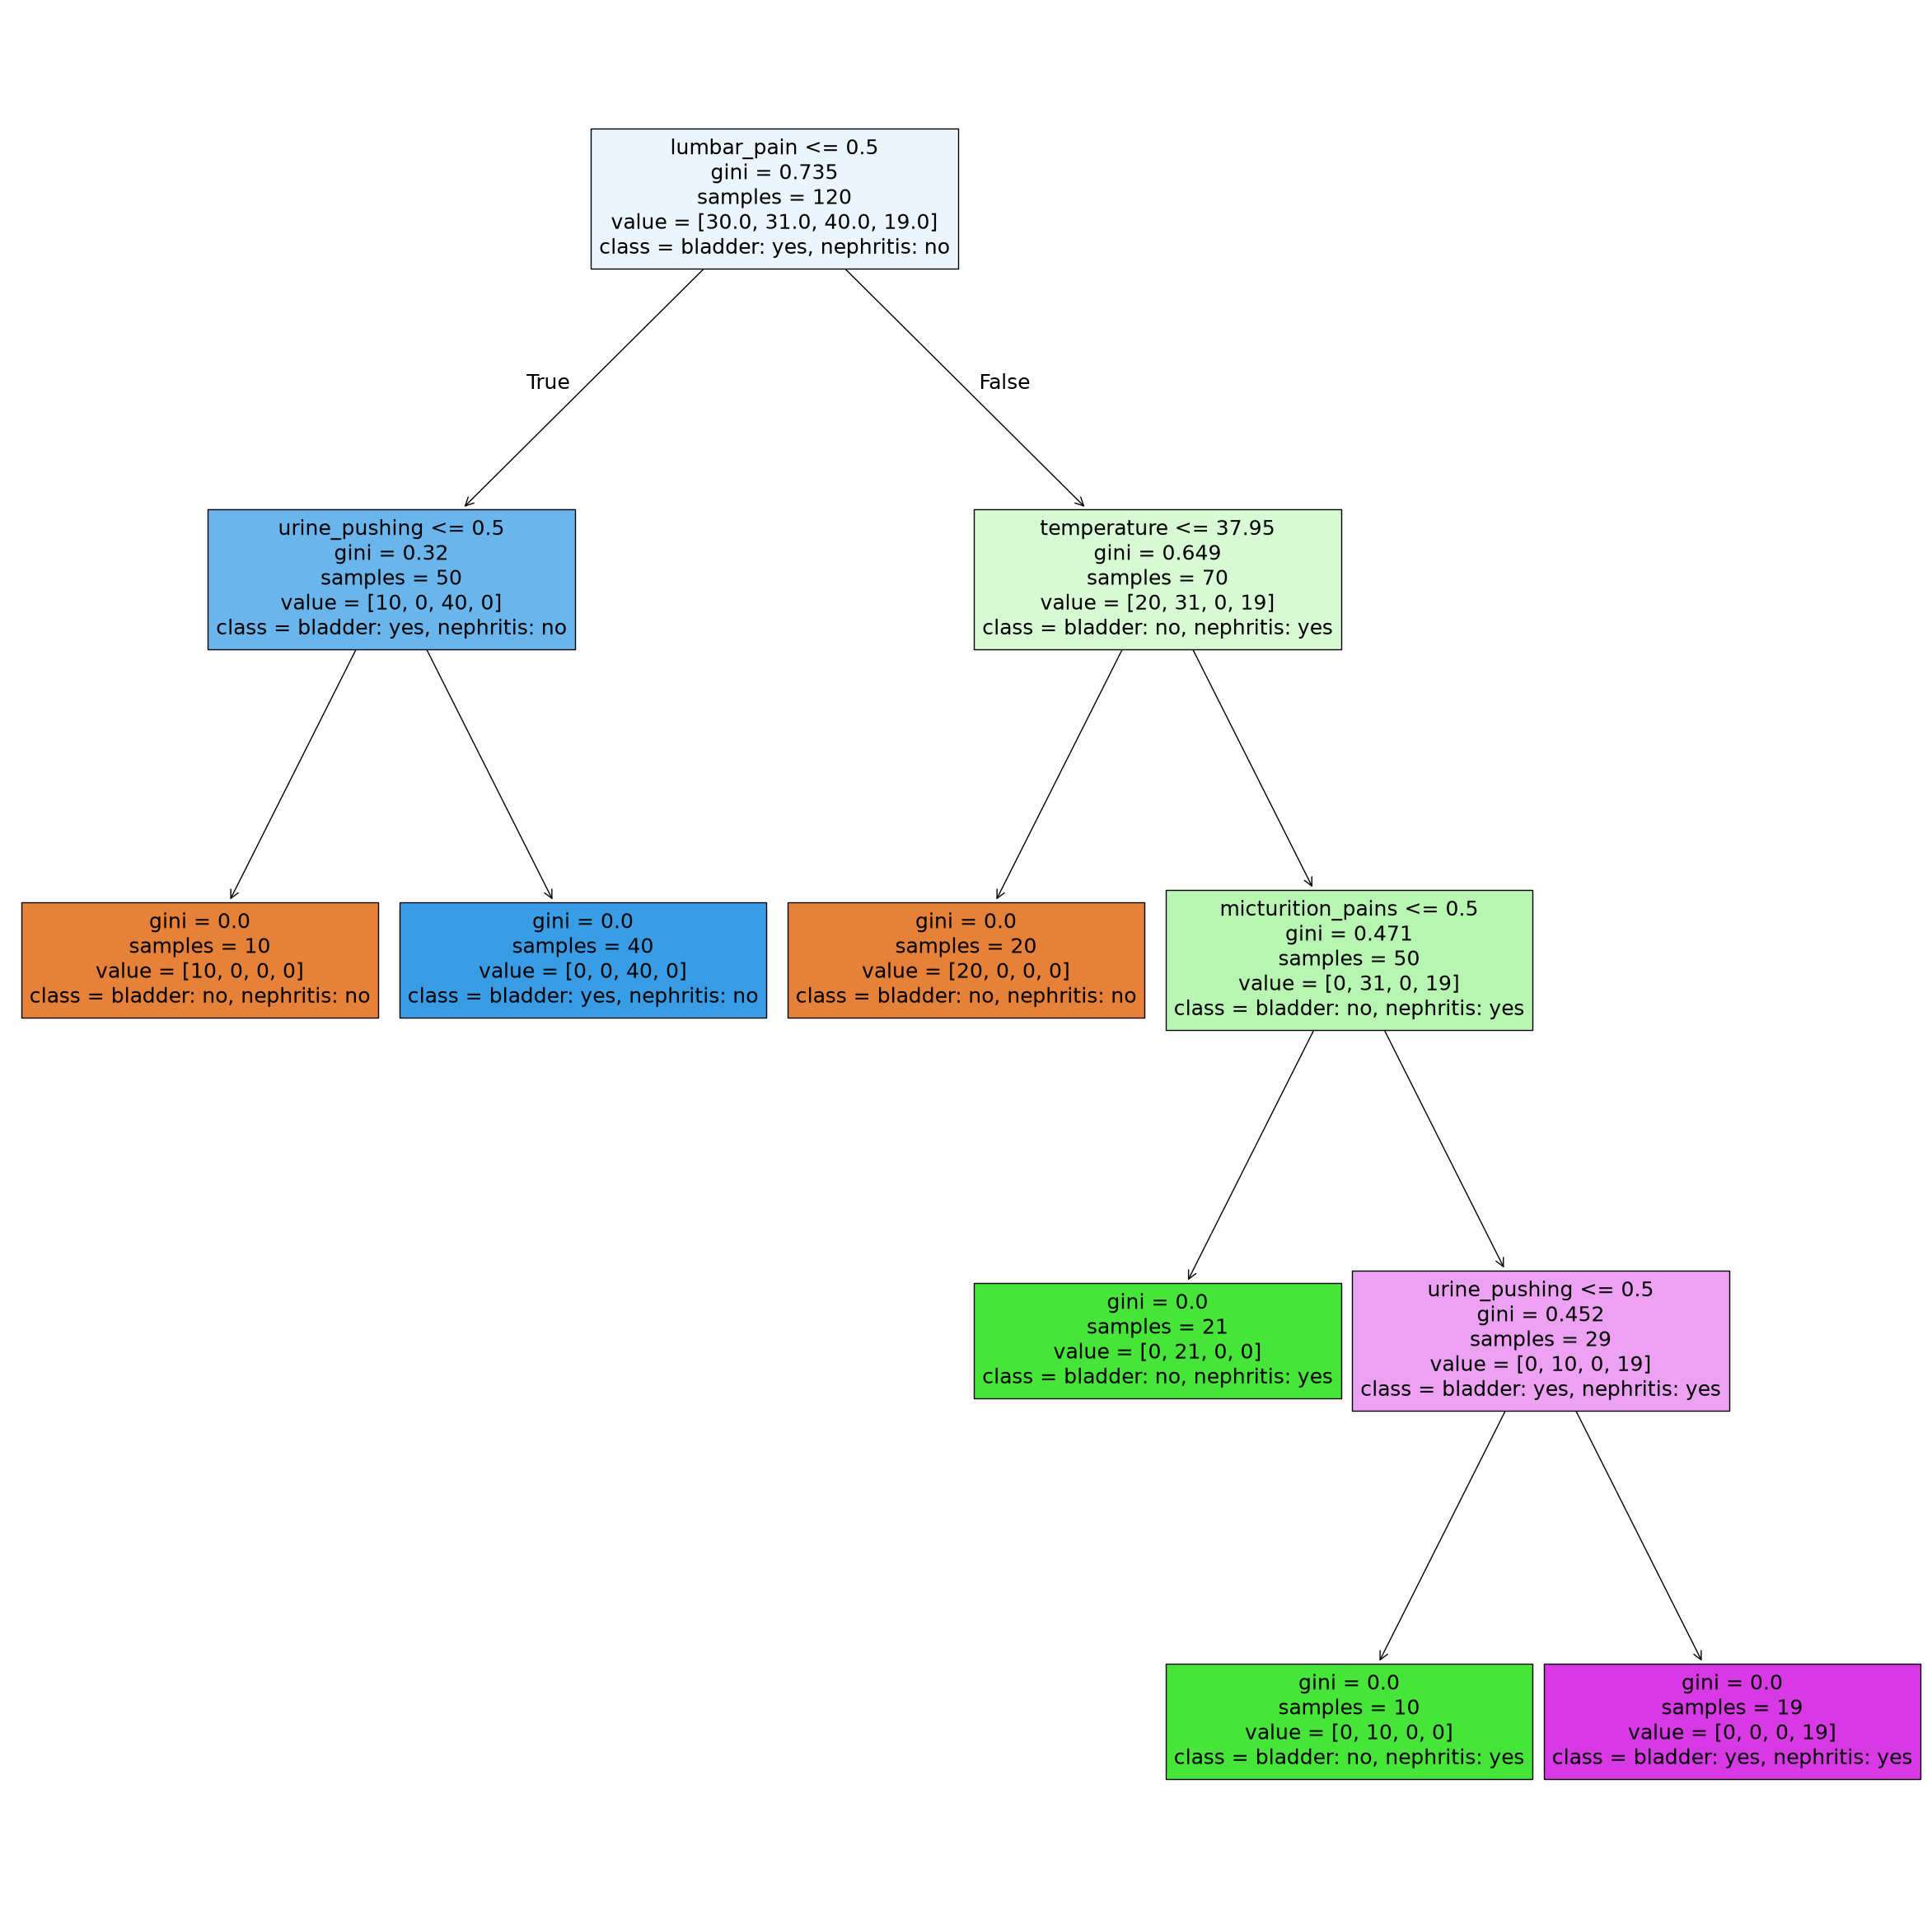

In [6]:
decision_tree = DecisionTreeClassifier(random_state=552)
decision_tree.fit(x, y)
plt.figure(figsize=[30, 30])
plot_tree(decision_tree, feature_names=x.columns, class_names=decision_tree.classes_, filled=True)
plt.show()

### (c) Convert the decision rules

In [7]:
# CODE USED FROM:
# https://www.kdnuggets.com/2017/05/simplifying-decision-tree-interpretation-decision-rules-python.html
# As recommended by the footnote

def tree_to_code(tree, feature_names):
	"""
	Outputs a decision tree model as a Python function
	
	Parameters:
	-----------
	tree: decision tree model
		The decision tree to represent as a function
	feature_names: list
		The feature names of the dataset used for building the decision tree
	"""

	tree_ = tree.tree_
	feature_name = [
		feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
		for i in tree_.feature
	]
	print("def tree({}):".format(", ".join(feature_names)))

	def recurse(node, depth):
		indent = "  " * depth
		if tree_.feature[node] != _tree.TREE_UNDEFINED:
			name = feature_name[node]
			threshold = tree_.threshold[node]
			print("{}if {} <= {}:".format(indent, name, threshold))
			recurse(tree_.children_left[node], depth + 1)
			print("{}else:  # if {} > {}".format(indent, name, threshold))
			recurse(tree_.children_right[node], depth + 1)
		else:
			print("{}return {}".format(indent, tree.classes_[np.argmax(tree_.value[node])])) # modified to display classes by name

	recurse(0, 1)

In [8]:
print(decision_tree.classes_)
tree_to_code(decision_tree, list(x.columns))

['bladder: no, nephritis: no' 'bladder: no, nephritis: yes'
 'bladder: yes, nephritis: no' 'bladder: yes, nephritis: yes']
def tree(temperature, nausea, lumbar_pain, urine_pushing, micturition_pains, urethra_issues):
  if lumbar_pain <= 0.5:
    if urine_pushing <= 0.5:
      return bladder: no, nephritis: no
    else:  # if urine_pushing > 0.5
      return bladder: yes, nephritis: no
  else:  # if lumbar_pain > 0.5
    if temperature <= 37.95000076293945:
      return bladder: no, nephritis: no
    else:  # if temperature > 37.95000076293945
      if micturition_pains <= 0.5:
        return bladder: no, nephritis: yes
      else:  # if micturition_pains > 0.5
        if urine_pushing <= 0.5:
          return bladder: no, nephritis: yes
        else:  # if urine_pushing > 0.5
          return bladder: yes, nephritis: yes




**There are 6 rules that are very interpretable:**


IF lumbar_pain <= 0.5 and urine_pushing <= 0.5,
THEN neither

IF lumbar_pain <= 0.5 and urine_pushing > 0.5,
THEN bladder only

IF lumbar_pain > 0.5 and temperature <= 37.95000076293945,
THEN neither

IF lumbar_pain > 0.5 and temperature > 37.95000076293945 and micturition_pains <= 0.5,
THEN nephritis only

IF lumbar_pain > 0.5 and temperature > 37.95000076293945 and micturition_pains > 0.5 and urine_pushing <= 0.5,
THEN nephritis only

IF lumbar_pain > 0.5 and temperature > 37.95000076293945 and micturition_pains > 0.5 and urine_pushing > 0.5,
THEN both

### (d) Cost Complexity Pruning

In [9]:
pruning = decision_tree.cost_complexity_pruning_path(x, y)
alpha_values = pruning.ccp_alphas[:-1]
print(alpha_values)

[0.         0.09816667 0.13333333 0.182     ]


In [10]:
pruning_tree = DecisionTreeClassifier(random_state=552)
five_fold_cross_validation = GridSearchCV(pruning_tree, {'ccp_alpha': alpha_values}, cv=5)
five_fold_cross_validation.fit(x, y)
output = pd.DataFrame({'alpha': alpha_values, 'accuracy': five_fold_cross_validation.cv_results_['mean_test_score']})
output

,alpha,accuracy
0,0.000000,0.958333
1,0.098167,0.775000
2,0.133333,0.716667
3,0.182000,0.600000


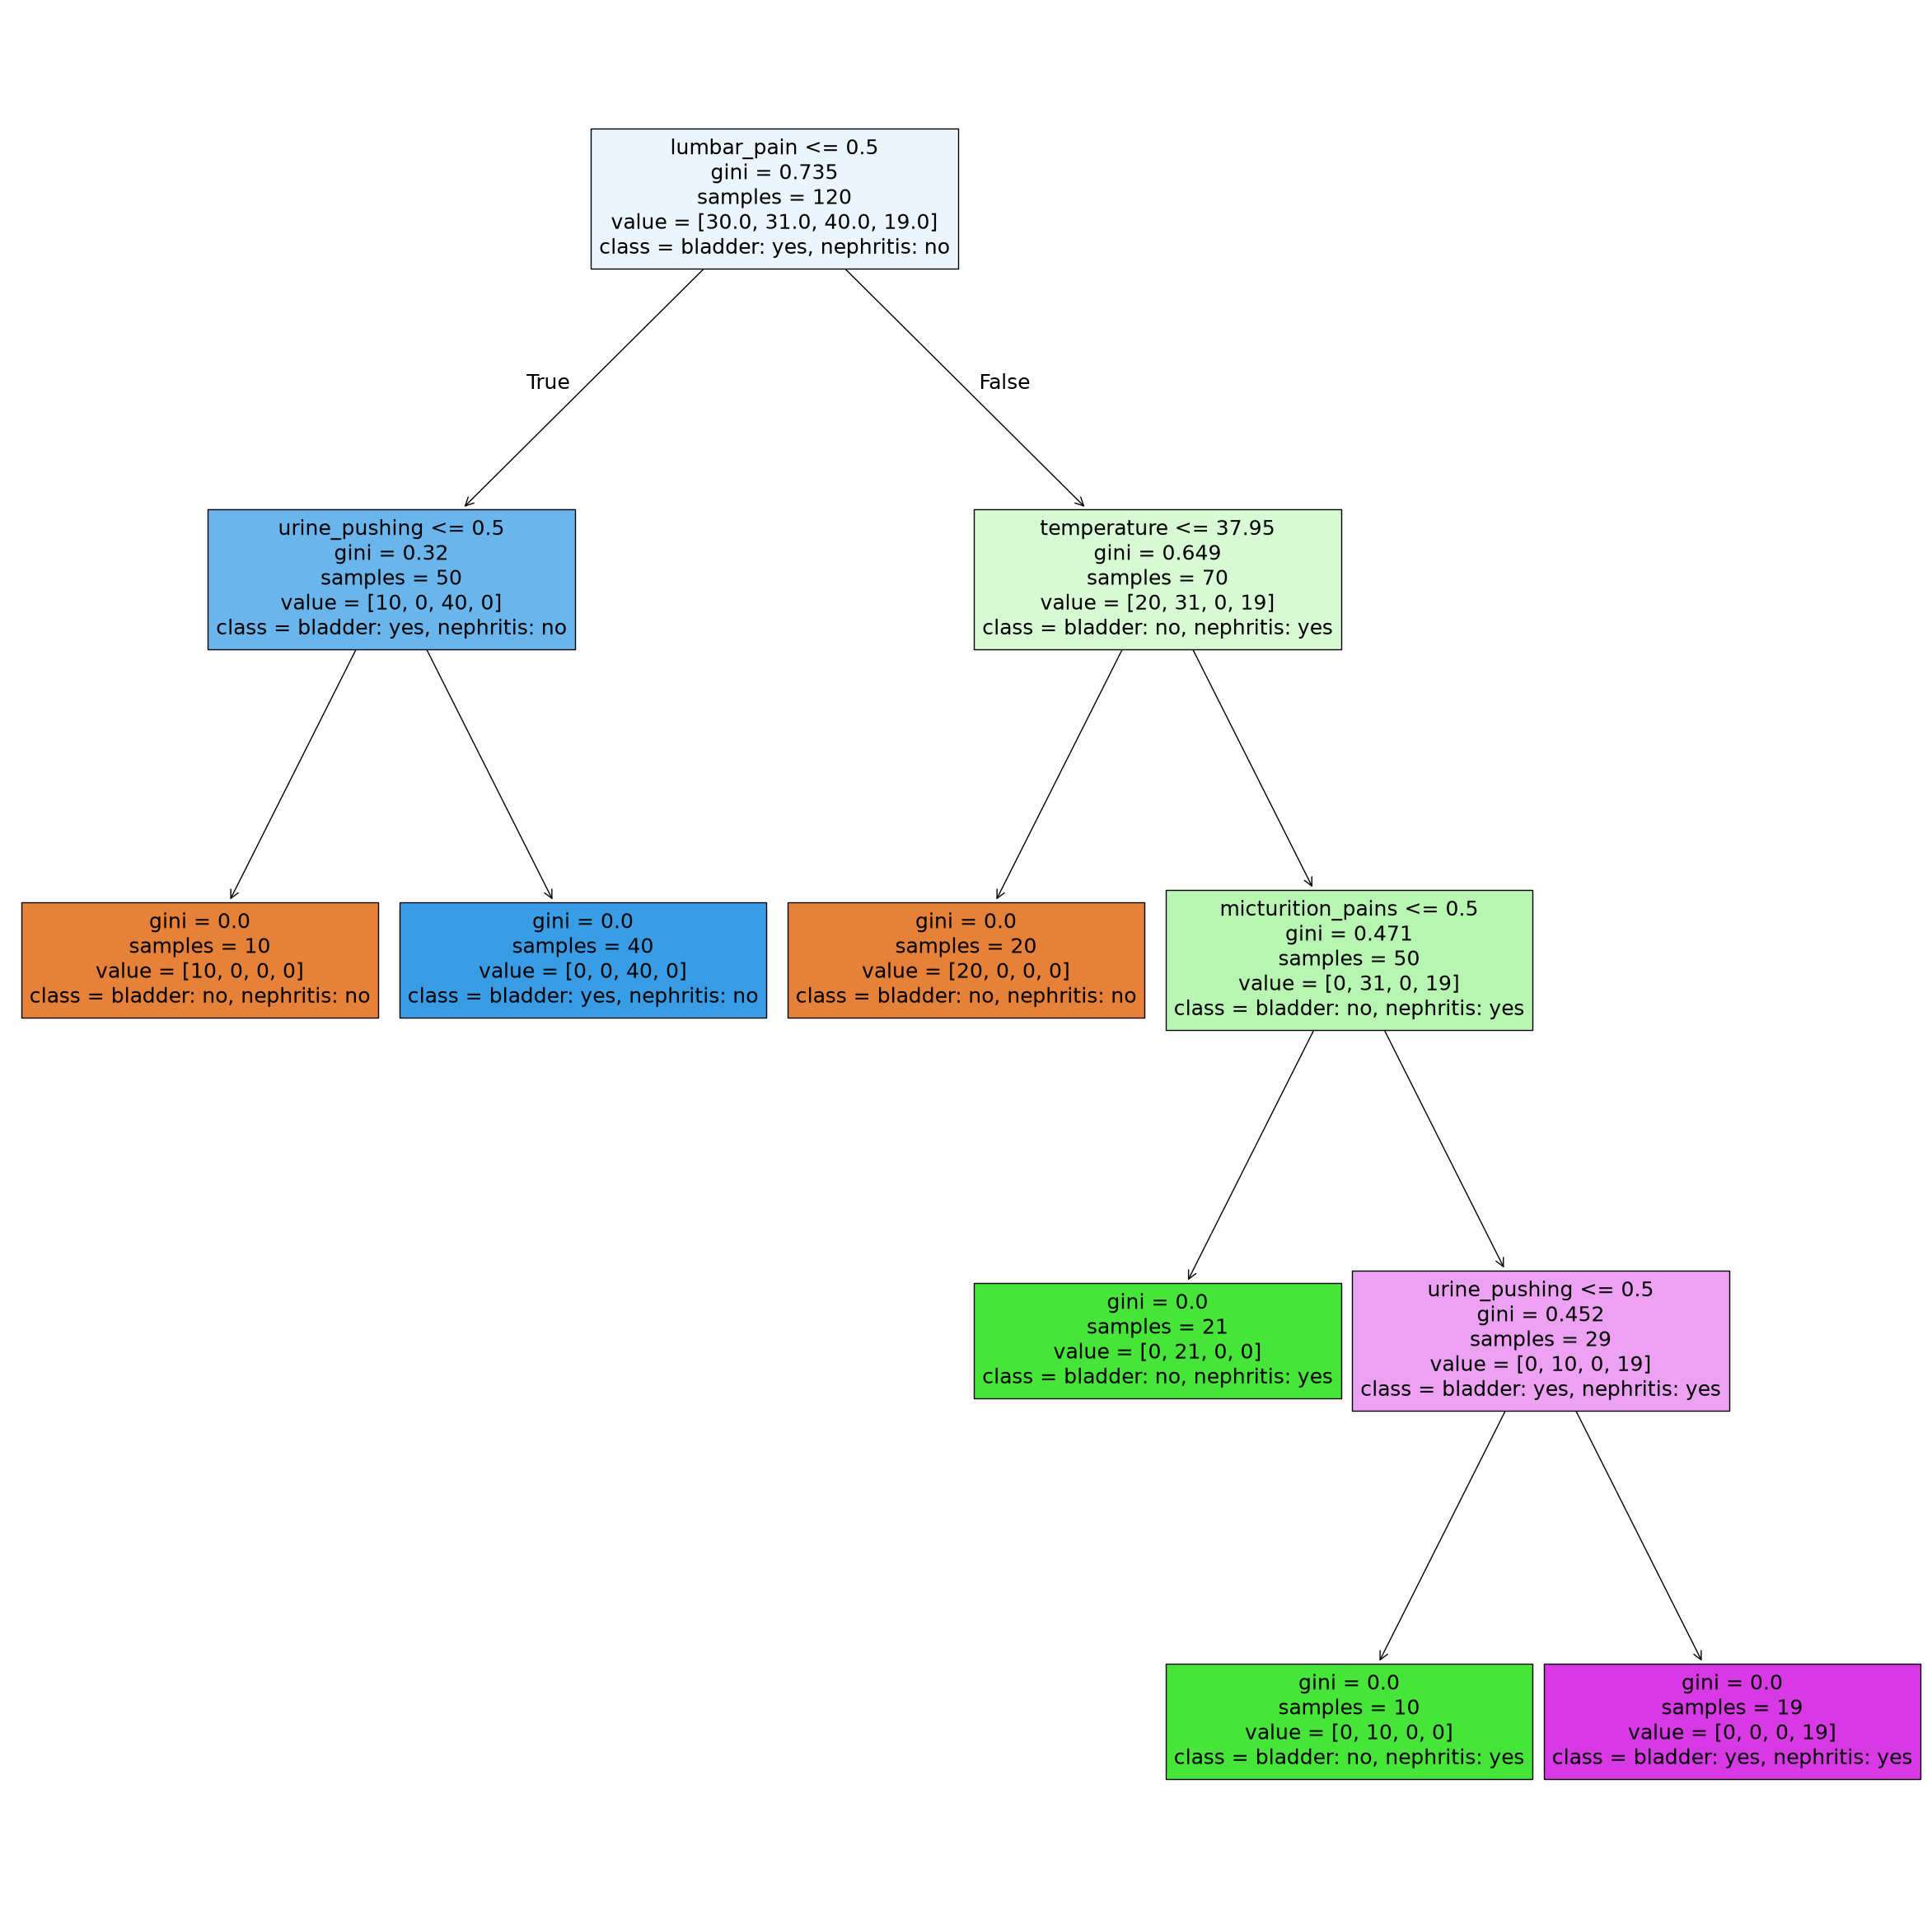

In [11]:
plt.figure(figsize=[30, 30])
plot_tree(decision_tree, feature_names=x.columns, class_names=decision_tree.classes_, filled=True)
plt.show()

The alpha value of 0 has the highest accuracy of 0.958 which means that pruning is not necessary. Removing one step would come at a penalty 0.183 accuracy which is not worth the slight decrease in complexity. So, the final tree is the same as the original tree. The rules are very interpretable as seen in part (c).

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [12]:
data_path_2 = '../Homework 5 Data/communities.csv'
name_path_2 = '../Homework 5 Data/communities.names'
columns_2 = []
for line in open(name_path_2):
    if line.startswith('@attribute'):
        columns_2.append(line.split()[1])

df_2 = pd.read_csv(data_path_2, names=columns_2, na_values='?')

train_df_2 = df_2.iloc[:1495]
test_df_2 = df_2.iloc[1495:]

df_2

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.90,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1989,12,NaN,NaN,TempleTerracecity,10,0.01,0.40,0.10,0.87,0.12,...,0.01,0.28,0.05,NaN,NaN,NaN,NaN,0.00,NaN,0.09
1990,6,NaN,NaN,Seasidecity,10,0.05,0.96,0.46,0.28,0.83,...,0.02,0.37,0.20,NaN,NaN,NaN,NaN,0.00,NaN,0.45
1991,9,9.0,80070.0,Waterburytown,10,0.16,0.37,0.25,0.69,0.04,...,0.08,0.32,0.18,0.08,0.06,0.78,0.0,0.91,0.28,0.23
1992,25,17.0,72600.0,Walthamcity,10,0.08,0.51,0.06,0.87,0.22,...,0.03,0.38,0.33,0.02,0.02,0.79,0.0,0.22,0.18,0.19


### (b) Missing values

In [13]:
train_df_2.drop(columns=['state', 'county', 'community', 'communityname', 'fold'], inplace=True)
test_df_2.drop(columns=['state', 'county', 'community', 'communityname', 'fold'], inplace=True)

data_imputation = SimpleImputer(strategy='mean')
train_df_2 = pd.DataFrame(data_imputation.fit_transform(train_df_2), columns=train_df_2.columns)
test_df_2 = pd.DataFrame(data_imputation.transform(test_df_2), columns=test_df_2.columns)

print(train_df_2.shape) 
train_df_2

(1495, 123)


,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.12,0.26,0.20,0.060000,0.040000,0.900000,0.500000,0.32,0.140000,0.20
1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,0.02,0.12,0.45,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.67
2,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,0.01,0.21,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.43
3,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,0.02,0.39,0.28,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.12
4,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,0.04,0.09,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1490,0.00,0.59,0.01,0.69,1.00,0.07,0.41,0.28,0.23,0.57,...,0.02,0.14,0.22,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03
1491,0.16,0.62,0.03,0.74,0.48,0.42,0.44,0.57,0.40,0.25,...,0.07,0.40,0.14,0.070000,0.050000,0.850000,0.500000,0.61,0.190000,0.20
1492,0.01,0.36,0.95,0.24,0.03,0.01,0.44,0.42,0.27,0.63,...,0.03,0.12,0.01,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.30
1493,0.06,0.53,0.01,0.98,0.05,0.01,0.40,0.40,0.24,0.29,...,0.08,0.15,0.02,0.163975,0.080502,0.713054,0.451883,0.00,0.190753,0.03


### (c) Plot a correlation matrix

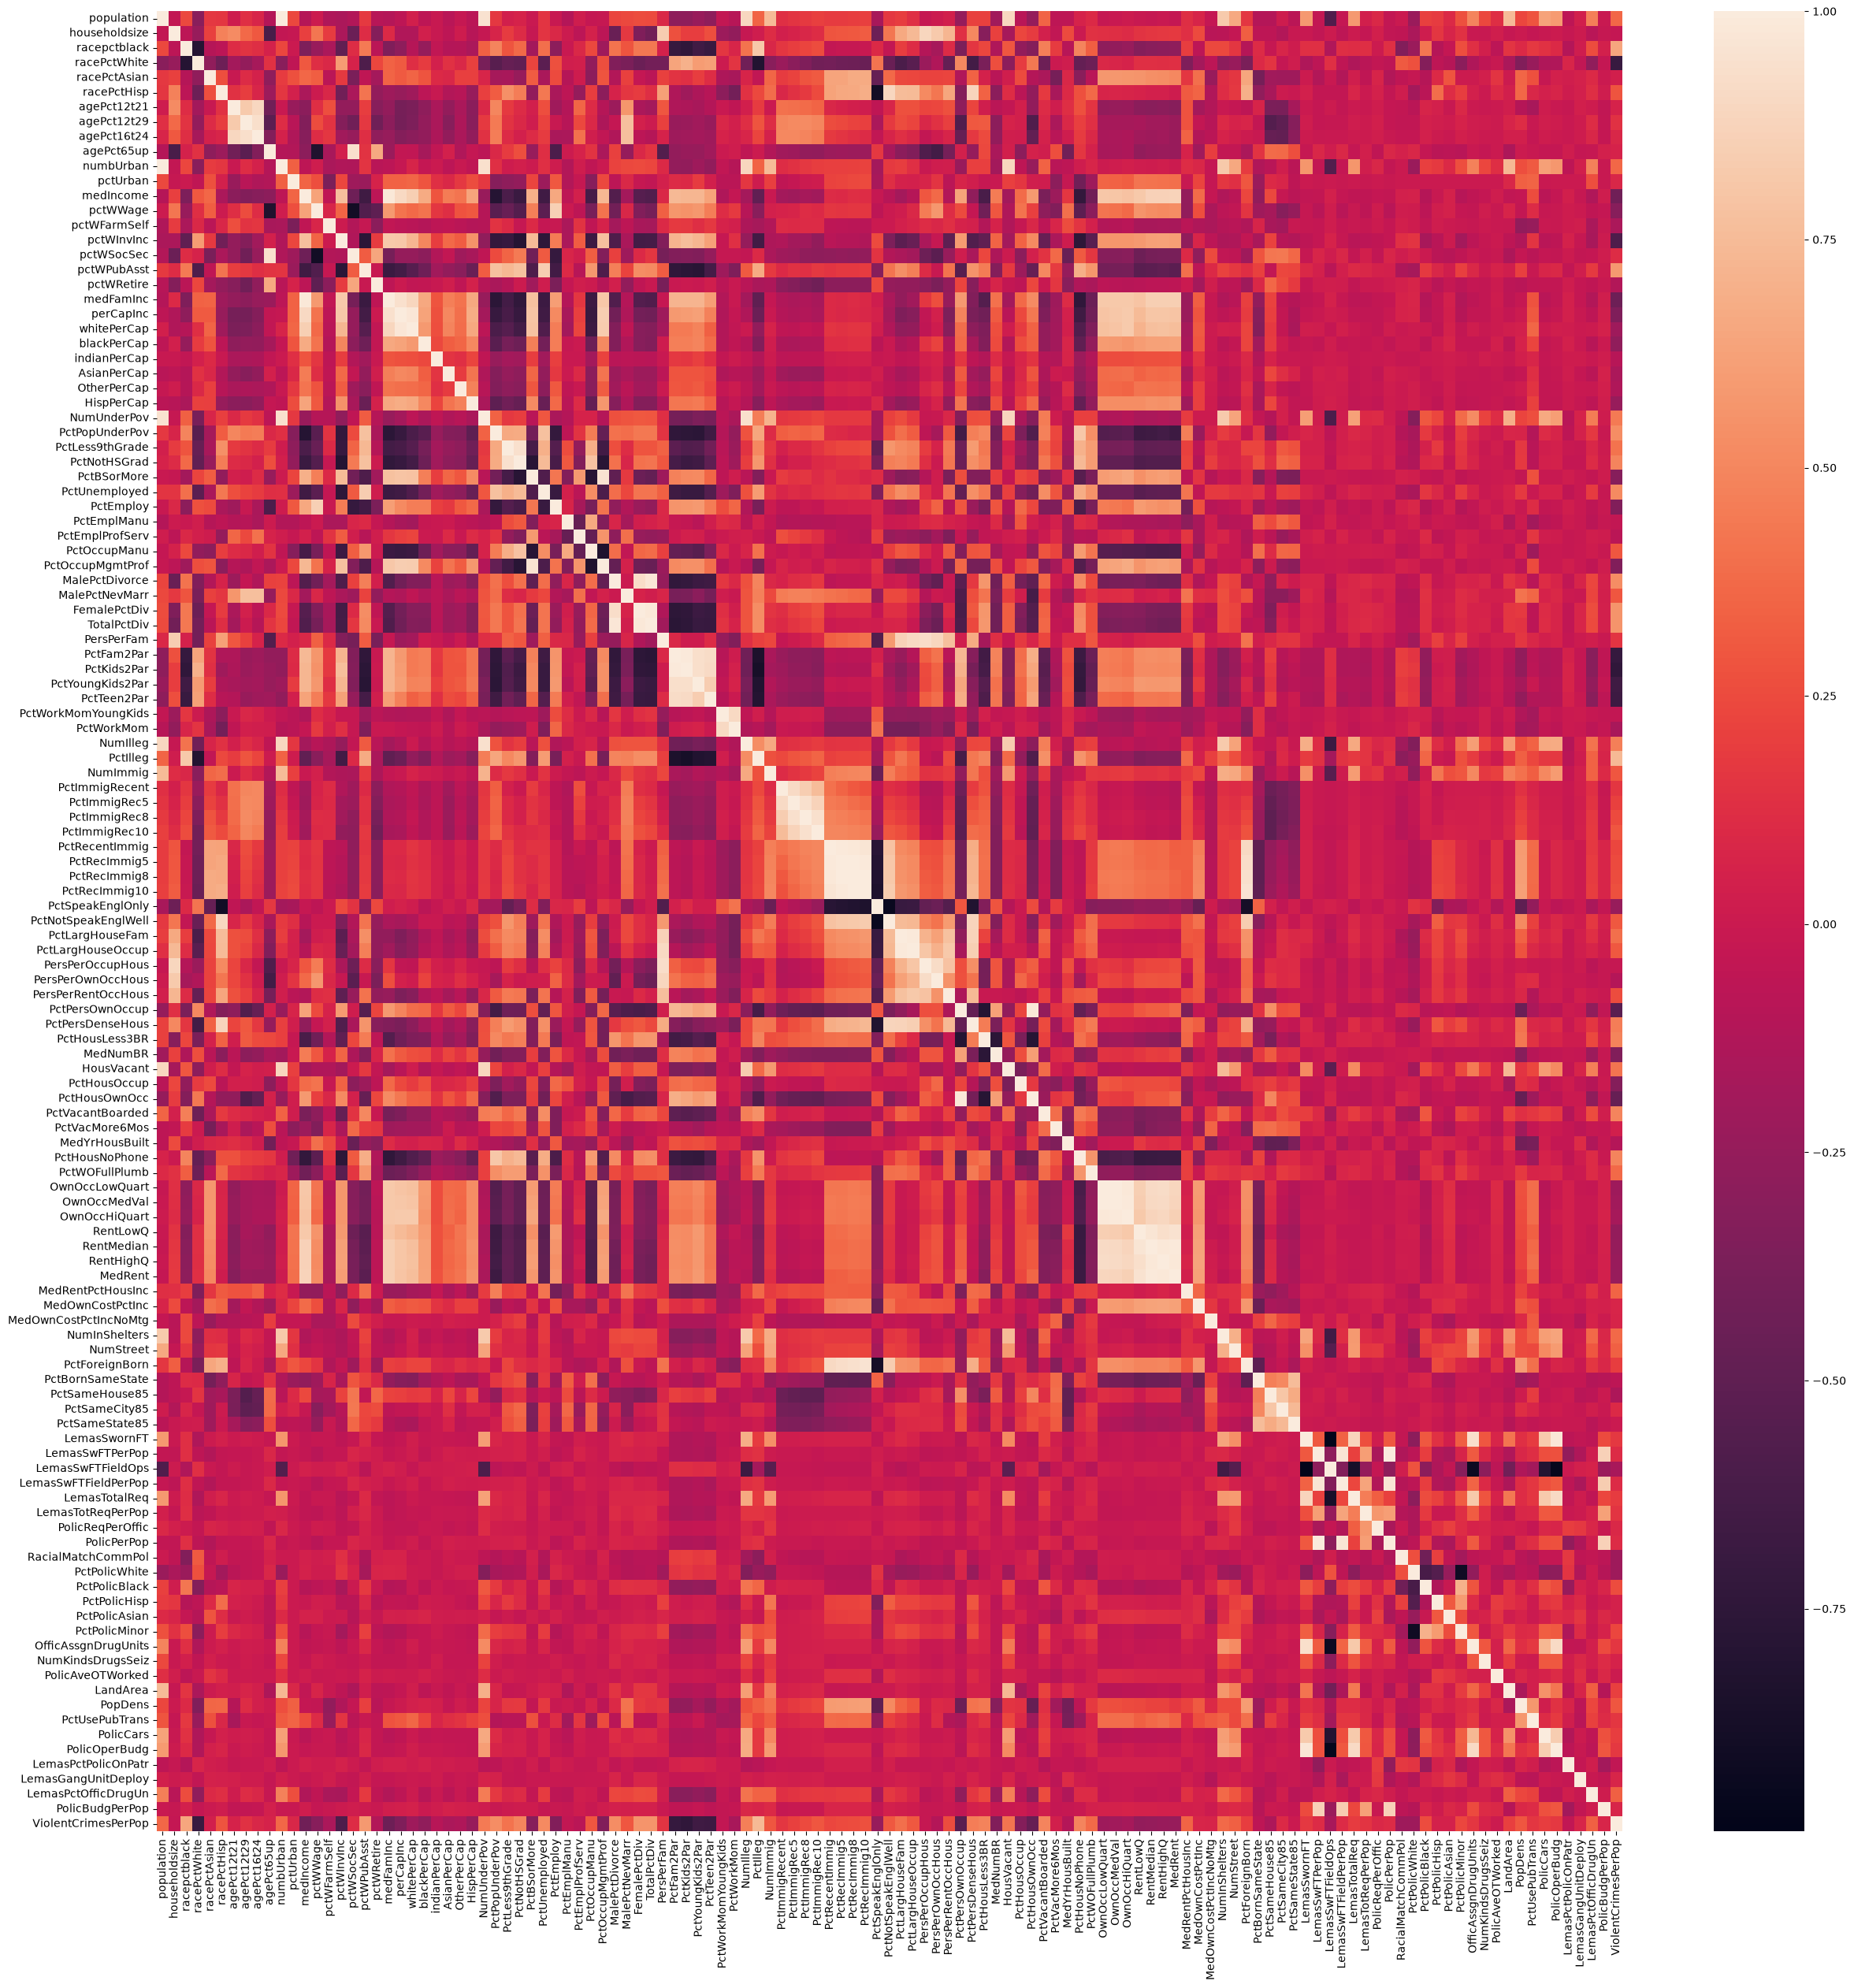

In [14]:
plt.figure(figsize=[30, 30])
correlation_matrix = train_df_2.corr()
sns.heatmap(correlation_matrix)
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [15]:
CV_df_2 = train_df_2.drop(columns=['ViolentCrimesPerPop'])
CV = CV_df_2.std() / CV_df_2.mean()
CV = CV.sort_values(ascending=False)
CV

NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
                         ...   
NumKindsDrugsSeiz      0.144382
RacialMatchCommPol     0.134853
PctPolicWhite          0.122813
LemasPctPolicOnPatr    0.115739
LemasSwFTFieldOps      0.064288
Length: 122, dtype: float64

### (e) Scatter plots and box plots for highest CV features

In [16]:
num_features = math.floor(math.sqrt(128))
print(f'{num_features} features')

CV_features = CV.head(num_features).index
print(CV_features)

11 features
Index(['NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig',
       'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'numbUrban',
       'HousVacant', 'LandArea', 'racePctHisp'],
      dtype='str')


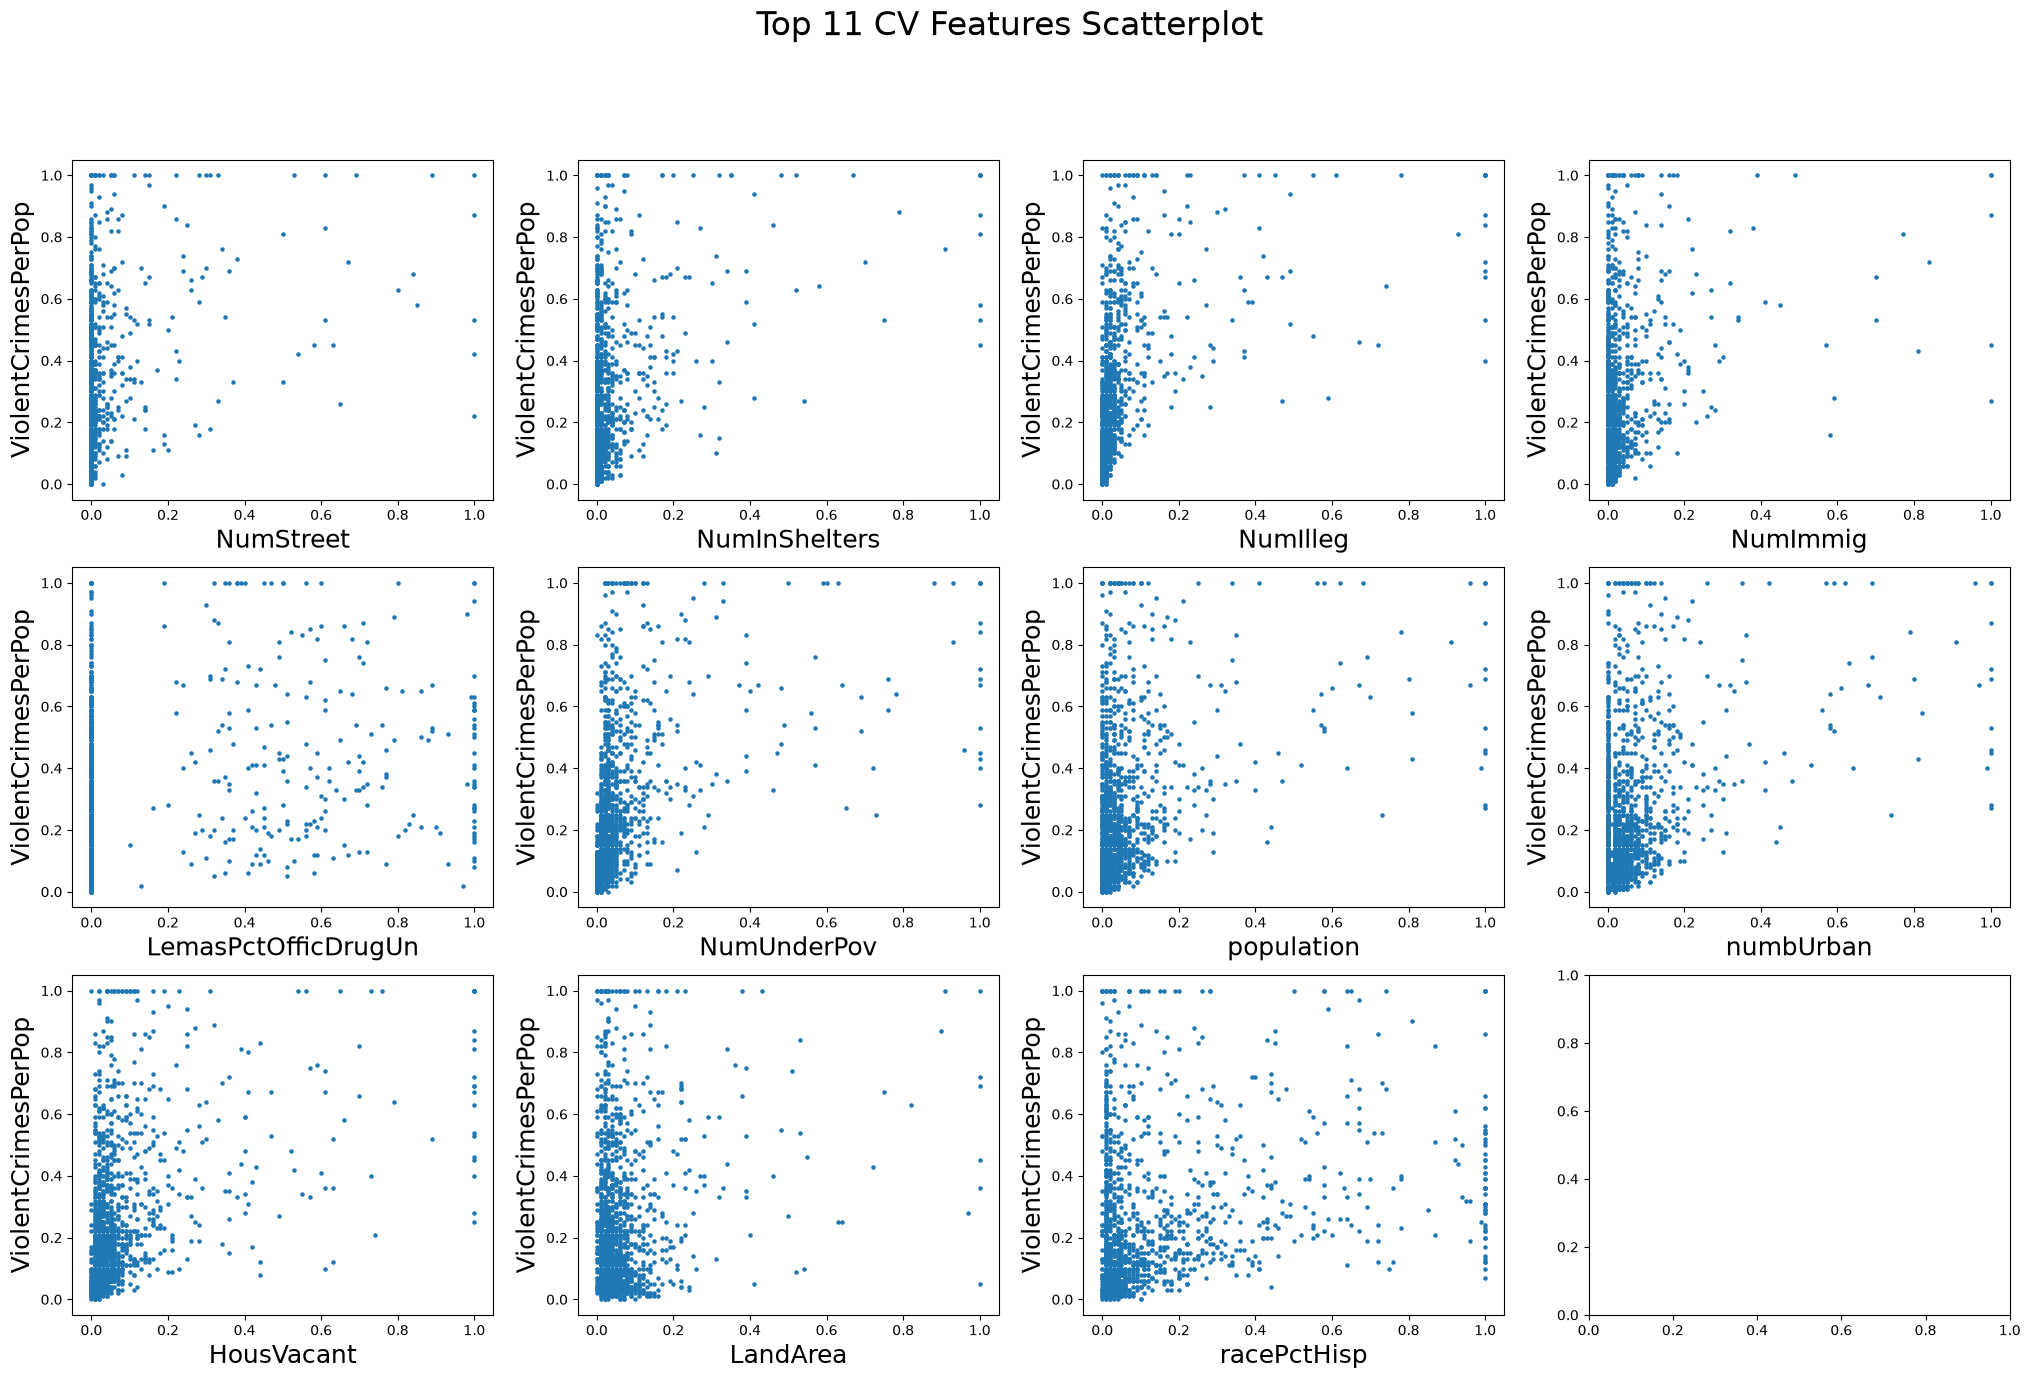

In [17]:
fig, axes = plt.subplots(3, 4, figsize=[25, 15])
axes = axes.flatten()

for i, feature in enumerate(CV_features):
    axes[i].scatter(train_df_2[feature], train_df_2['ViolentCrimesPerPop'], s=5)
    axes[i].set_xlabel(feature, fontsize=18)
    axes[i].set_ylabel('ViolentCrimesPerPop', fontsize=18)

plt.suptitle('Top 11 CV Features Scatterplot', fontsize=24)
plt.show()

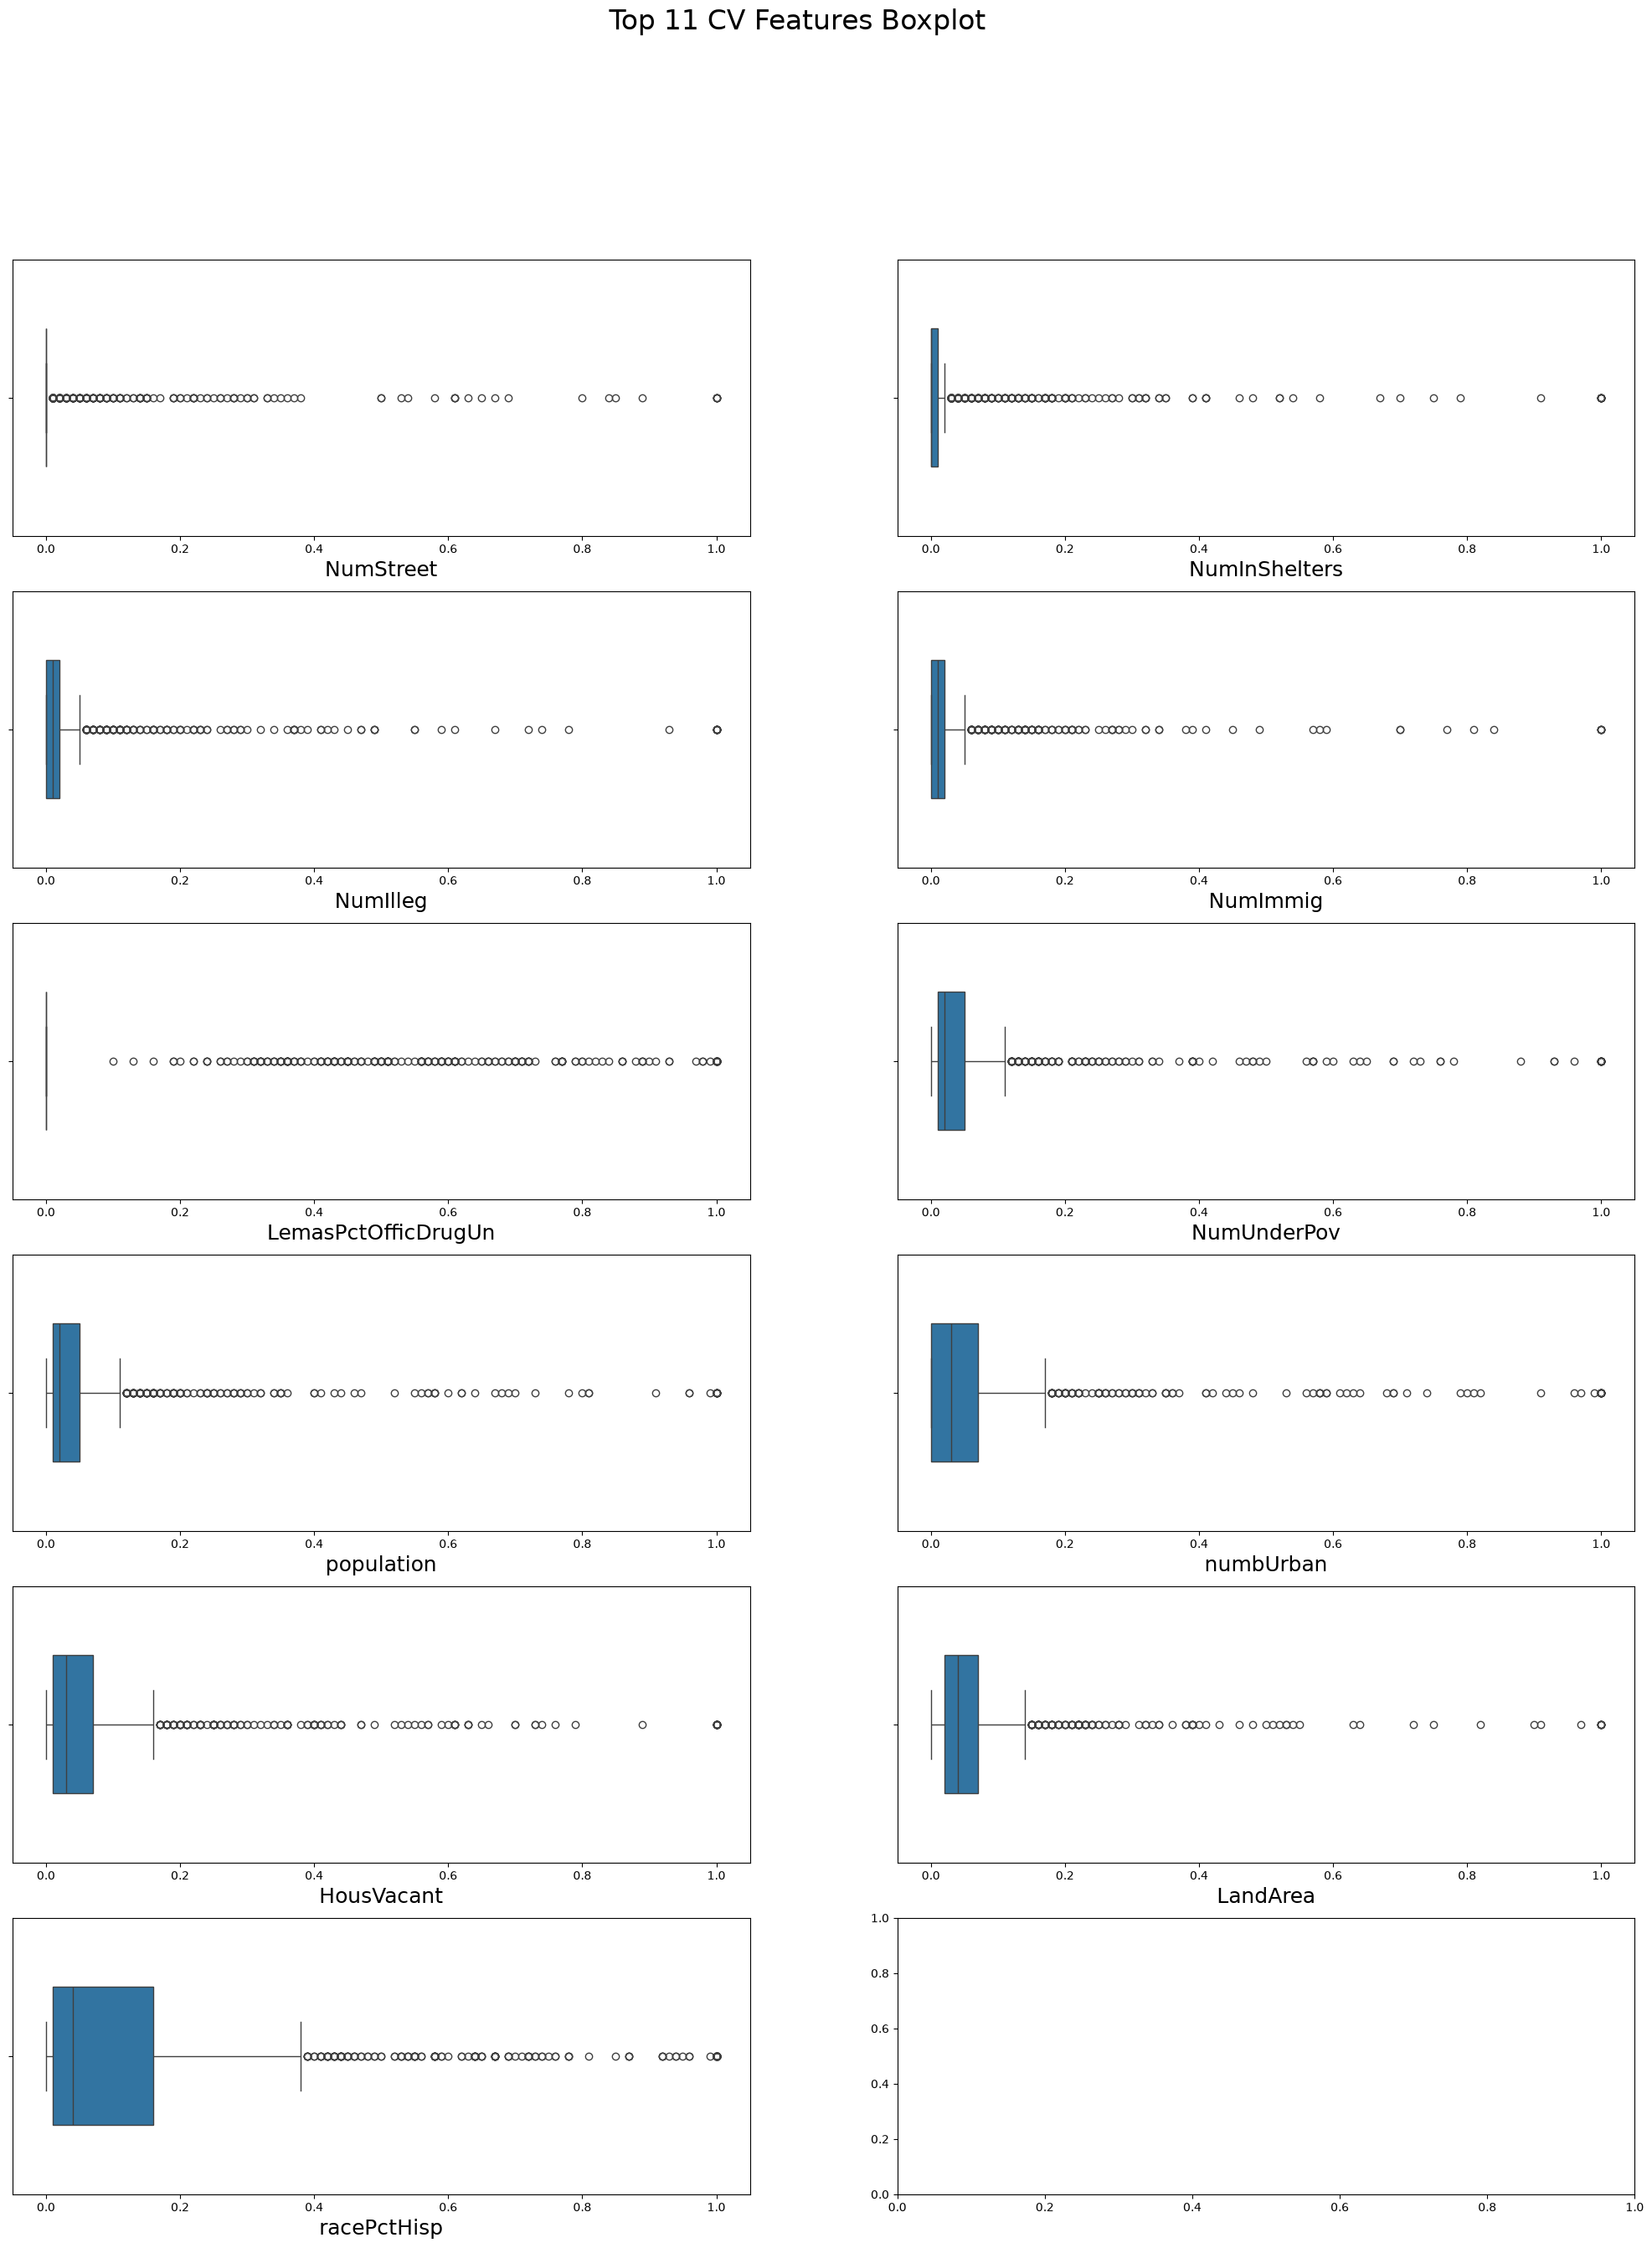

In [18]:
fig, axes = plt.subplots(6, 2, figsize=[25, 30])
axes = axes.flatten()

for i, feature in enumerate(CV_features):
    sns.boxplot(x=train_df_2[feature], ax=axes[i], width=0.5)
    axes[i].set_xlabel(feature, fontsize=18)

fig.suptitle('Top 11 CV Features Boxplot', fontsize=24)
plt.show()

From the scatterplots, numbUrban and NumUnderPov seem to have a slight positive relationship with the target (ViolentCrimesPerPop). However, almost no pattern is visible for the other features. Since the values are mostly clustered around zero, it's difficult to observe patterns by eye.

The data is very right skewed as seen by the boxplots. Interestingly, LemasPctOfficDrugUn and NumStreet have their box at 0 since over 75% of the values are zero.

We can't draw conclusions from just these plots. High CV values does not guarantee significance.

### (f) Fit a linear model

In [19]:
x_train_2 = train_df_2.drop(columns=['ViolentCrimesPerPop'])
x_test_2 = test_df_2.drop(columns=['ViolentCrimesPerPop'])

y_train_2 = train_df_2['ViolentCrimesPerPop']
y_test_2 = test_df_2['ViolentCrimesPerPop']

linear_model = LinearRegression()
linear_model.fit(x_train_2, y_train_2)
y_pred_2 = linear_model.predict(x_test_2)
mse_linear = mean_squared_error(y_test_2, y_pred_2)
print('Linear Model')
print(f'MSE: {mse_linear}')

Linear Model
MSE: 0.018141971135530104


### (g) Fit a ridge regression model

In [20]:
C_list = [0.01, 0.05, 0.1, 0.5, 1, 5, 10, 25, 50, 100]

ridge_model = RidgeCV(alphas=C_list, cv=5)
ridge_model.fit(x_train_2, y_train_2)
y_pred_2_ridge = ridge_model.predict(x_test_2)
mse_ridge = mean_squared_error(y_test_2, y_pred_2_ridge)
print('Ridge Regression')
print(f'MSE: {mse_ridge}')
print(f'Lambda: {ridge_model.alpha_}')

Ridge Regression
MSE: 0.017499229760215458
Lambda: 5.0


### (h) Fit a LASSO model

In [21]:
C_list = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1, 5, 10, 25, 50, 100]

lasso_model = LassoCV(alphas=C_list, cv=5, max_iter=1000, random_state=552)
lasso_model.fit(x_train_2, y_train_2)
y_pred_2_lasso = lasso_model.predict(x_test_2)
mse_lasso = mean_squared_error(y_test_2, y_pred_2_lasso)
print('LASSO Regression')
print(f'MSE: {mse_lasso}')
print(f'Lambda: {lasso_model.alpha_}')
print('Features:')
print(x_train_2.columns[lasso_model.coef_ != 0])

LASSO Regression
MSE: 0.017556116076652563
Lambda: 0.0005
Features:
Index(['racepctblack', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWInvInc',
       'pctWPubAsst', 'pctWRetire', 'indianPerCap', 'AsianPerCap',
       'OtherPerCap', 'PctPopUnderPov', 'MalePctDivorce', 'PctKids2Par',
       'PctYoungKids2Par', 'PctWorkMom', 'PctIlleg', 'PctRecImmig10',
       'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant', 'PctHousOccup',
       'PctVacantBoarded', 'PctVacMore6Mos', 'PctWOFullPlumb', 'MedRent',
       'MedRentPctHousInc', 'MedOwnCostPctIncNoMtg', 'NumStreet',
       'PctForeignBorn', 'PctSameCity85', 'PolicReqPerOffic', 'PopDens',
       'LemasGangUnitDeploy', 'LemasPctOfficDrugUn'],
      dtype='str')


In [22]:
scaler = StandardScaler()
x_train_2_scaled = scaler.fit_transform(x_train_2)
x_test_2_scaled = scaler.transform(x_test_2)

lasso_model_scaled = LassoCV(alphas=C_list, cv=5, max_iter=1000, random_state=552)
lasso_model_scaled.fit(x_train_2_scaled, y_train_2)
y_pred_2_lasso_scaled = lasso_model_scaled.predict(x_test_2_scaled)
mse_lasso_scaled = mean_squared_error(y_test_2, y_pred_2_lasso_scaled)
print('Standardized LASSO Regression')
print(f'MSE: {mse_lasso_scaled}')
print(f'Lambda: {lasso_model_scaled.alpha_}')
print('Features:')
print(x_train_2.columns[lasso_model_scaled.coef_ != 0])

Standardized LASSO Regression
MSE: 0.017758149260213713
Lambda: 0.001
Features:
Index(['racepctblack', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage',
       'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire',
       'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap',
       'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade',
       'PctEmploy', 'PctEmplManu', 'MalePctDivorce', 'MalePctNevMarr',
       'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par',
       'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec5',
       'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup',
       'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'HousVacant',
       'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt',
       'PctWOFullPlumb', 'RentLowQ', 'MedRent', 'MedRentPctHousInc',
       'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters',
       'NumStreet', 'PctForeignBorn', 'Pct

The unstandardized LASSO model had a slightly better test error (MSE: 0.0176) than the standardized model (0.0178), however the difference is very minimal. 33 of the features selected overlap between the models. LemasPctOfficDrugUn was selected by only the unstandardized model. And the standardized model has 35 additional features.

### (i) Fit a PCR model

In [23]:
pca = PCA()
x_train_2_pca = pca.fit_transform(x_train_2_scaled)
x_test_2_pca = pca.transform(x_test_2_scaled)

errors = []
for M in range(1, x_train_2_pca.shape[1] + 1):
    model = LinearRegression()
    score = cross_val_score(model, x_train_2_pca[:, :M], y_train_2, scoring='neg_mean_squared_error', cv=5)
    errors.append(-score.mean())

M = np.argmin(errors) + 1
PCR_model = LinearRegression()
PCR_model.fit(x_train_2_pca[:, :M], y_train_2)
y_pred_2_PCR = PCR_model.predict(x_test_2_pca[:, :M])
mse_PCR = mean_squared_error(y_test_2, y_pred_2_PCR)

print('PCR')
print(f'MSE: {mse_PCR}')
print(f'M: {M}')

PCR
MSE: 0.01839293123038779
M: 95


### (j) Fit a boosting tree

In [24]:
alphas = {'reg_alpha': [0, 0.001, 0.005, 0.01, 0.05, 0.1, 1, 10]}
search_model = XGBRegressor(random_state=552, max_depth=3, n_estimators=200, learning_rate=0.1)
XGBoost_model = GridSearchCV(search_model, alphas, cv=5, scoring='neg_mean_squared_error')
XGBoost_model.fit(x_train_2, y_train_2)
y_pred_2_XGB = XGBoost_model.predict(x_test_2)
mse_XGB = mean_squared_error(y_test_2, y_pred_2_XGB)
print('XGBoost Model')
print(f'MSE: {mse_XGB}')
print(f'Alpha: {XGBoost_model.best_params_['reg_alpha']}')

XGBoost Model
MSE: 0.016458244797750498
Alpha: 0


The best alpha is zero, which means that the L1 penalty is not helping.

Overall, the XGBoost model performed the best out of all the models with an MSE test error of 0.0165.